In [185]:
# %matplotlib ipympl
# %matplotlib widget
# %matplotlib inline

In [186]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
import math
from IPython.display import HTML

In [187]:
# This contains some functions for numerical solution of 2D Euler equations
# All students need to be familiar with all of these subroutines

# Compute internal energy from density and pressure
def internal_energy(rho, prs):
    return(prs/(gamma-1)/rho)

# Compute pressure from density and internal energy
def pressure(rho, eint):
    return((gamma-1)*rho*eint)

# Compute the fluxes
def flux_x(rho, vel_x, vel_y, prs):
    eint = internal_energy(rho,prs)
    ke = 0.5 * (vel_x*vel_x + vel_y*vel_y)
    return(np.array([rho*vel_x, rho*vel_x*vel_x + prs, rho*vel_x*vel_y, (rho*(eint+ke)+prs)*vel_x]))

def flux_y(rho, vel_x, vel_y, prs):
    eint = internal_energy(rho,prs)
    ke = 0.5 * (vel_x*vel_x + vel_y*vel_y)
    return(np.array([rho*vel_y, rho*vel_y*vel_x, rho*vel_y*vel_y + prs, (rho*(eint+ke)+prs)*vel_y]))
    
# Convert primitive quantities to conservative
def Prim2Cons(rho, vel_x, vel_y, prs):
    eint = internal_energy(rho,prs)
    ke = 0.5 * (vel_x*vel_x + vel_y*vel_y)
    return(np.array([rho, rho*vel_x, rho*vel_y, rho*(eint+ke)]))

# Convert conservative quantities to primitive  
def Cons2Prim(rho, rhou, rhov, rhoE):
    rho = rho
    vel_x = rhou/rho
    vel_y = rhov/rho
    Etot = rhoE/rho
    ke = 0.5 * (vel_x*vel_x + vel_y*vel_y)
    eint = Etot - ke
    prs = pressure(rho, eint)
    return(np.array([rho, vel_x, vel_y, prs]))

# Compute fluxes using the HLLC solver
def HLLC_x(rho_L, vel_x_L, vel_y_L, prs_L, rho_R, vel_x_R, vel_y_R, prs_R):
    vel_L = vel_x_L; vel_R = vel_x_R
    S_L = np.minimum( vel_L - np.sqrt(gamma * prs_L / rho_L), vel_R - np.sqrt(gamma * prs_R / rho_R) )
    S_R = np.maximum( vel_L + np.sqrt(gamma * prs_L / rho_L), vel_R + np.sqrt(gamma * prs_R / rho_R) )
    S_star = ( (prs_R - prs_L) + rho_L * vel_L * (S_L - vel_L) - rho_R * vel_R * (S_R - vel_R) ) \
             / ( rho_L * (S_L - vel_L) - rho_R * (S_R - vel_R) + 1e-16)
    E_L = internal_energy(rho_L, prs_L) + 0.5*(vel_x_L**2+vel_y_L**2)
    E_R = internal_energy(rho_R, prs_R) + 0.5*(vel_x_R**2+vel_y_R**2)

    U_L = Prim2Cons(rho_L, vel_x_L, vel_y_L, prs_L)
    U_R = Prim2Cons(rho_R, vel_x_R, vel_y_R, prs_R)
    
    U_starL = [np.ones(vel_L.shape),
               S_star,
               vel_y_L,
               E_L + (S_star - vel_L) * (S_star + prs_L / rho_L / (S_L - vel_L))]
    U_starL = np.array(U_starL) * rho_L * (S_L - vel_L) / (S_L - S_star)
    
    U_starR = [np.ones(vel_R.shape),
               S_star,
               vel_y_R,
               E_R + (S_star - vel_R) * (S_star + prs_R / rho_R / (S_R - vel_R))]             
    U_starR = np.array(U_starR) * rho_R * (S_R - vel_R) / (S_R - S_star)

    F_L = flux_x(rho_L, vel_x_L, vel_y_L, prs_L)
    F_R = flux_x(rho_R, vel_x_R, vel_y_R, prs_R)
    F_starL = F_L + S_L * (U_starL - U_L)
    F_starR = F_R + S_R * (U_starR - U_R)

    slow = False
    if slow:
        if (S_L >= 0.):
            Flux = F_L
        elif ( (S_L < 0.) and (S_star >= 0) ):
            Flux = F_starL
        elif ( (S_star < 0) and (S_R >= 0.) ):
            Flux = F_starR
        elif (S_R < 0.):
            Flux = F_R
        else:
            Flux = 0.

    Flux = np.zeros(vel_L.shape)
    Flux = np.where(S_L >= 0., F_L, Flux)
    Flux = np.where((S_L < 0.) & (S_star >= 0), F_starL, Flux)
    Flux = np.where((S_star < 0) & (S_R >= 0.), F_starR, Flux)
    Flux = np.where(S_R < 0., F_R, Flux)

    return(Flux)

# Compute fluxes using the HLLC solver
def HLLC_y(rho_L, vel_x_L, vel_y_L, prs_L, rho_R, vel_x_R, vel_y_R, prs_R):
    vel_L = vel_y_L; vel_R = vel_y_R
    S_L = np.minimum( vel_L - np.sqrt(gamma * prs_L / rho_L), vel_R - np.sqrt(gamma * prs_R / rho_R) )
    S_R = np.maximum( vel_L + np.sqrt(gamma * prs_L / rho_L), vel_R + np.sqrt(gamma * prs_R / rho_R) )
    S_star = ( (prs_R - prs_L) + rho_L * vel_L * (S_L - vel_L) - rho_R * vel_R * (S_R - vel_R) ) \
             / ( rho_L * (S_L - vel_L) - rho_R * (S_R - vel_R) + 1e-16)
    E_L = internal_energy(rho_L, prs_L) + 0.5*(vel_x_L**2+vel_y_L**2)
    E_R = internal_energy(rho_R, prs_R) + 0.5*(vel_x_R**2+vel_y_R**2)

    U_L = Prim2Cons(rho_L, vel_x_L, vel_y_L, prs_L)
    U_R = Prim2Cons(rho_R, vel_x_R, vel_y_R, prs_R)
    
    U_starL = [np.ones(vel_L.shape),
               vel_x_L,
               S_star,
               E_L + (S_star - vel_L) * (S_star + prs_L / rho_L / (S_L - vel_L))]
    U_starL = np.array(U_starL) * rho_L * (S_L - vel_L) / (S_L - S_star)
    
    U_starR = [np.ones(vel_R.shape),
               vel_x_R,
               S_star,
               E_R + (S_star - vel_R) * (S_star + prs_R / rho_R / (S_R - vel_R))]             
    U_starR = np.array(U_starR) * rho_R * (S_R - vel_R) / (S_R - S_star)

    F_L = flux_y(rho_L, vel_x_L, vel_y_L, prs_L)
    F_R = flux_y(rho_R, vel_x_R, vel_y_R, prs_R)
    F_starL = F_L + S_L * (U_starL - U_L)
    F_starR = F_R + S_R * (U_starR - U_R)

    slow = False
    if slow:
        if (S_L >= 0.):
            Flux = F_L
        elif ( (S_L < 0.) and (S_star >= 0) ):
            Flux = F_starL
        elif ( (S_star < 0) and (S_R >= 0.) ):
            Flux = F_starR
        elif (S_R < 0.):
            Flux = F_R
        else:
            Flux = 0.

    Flux = np.zeros(vel_L.shape)
    Flux = np.where(S_L >= 0., F_L, Flux)
    Flux = np.where((S_L < 0.) & (S_star >= 0), F_starL, Flux)
    Flux = np.where((S_star < 0) & (S_R >= 0.), F_starR, Flux)
    Flux = np.where(S_R < 0., F_R, Flux)
    
    return(Flux)

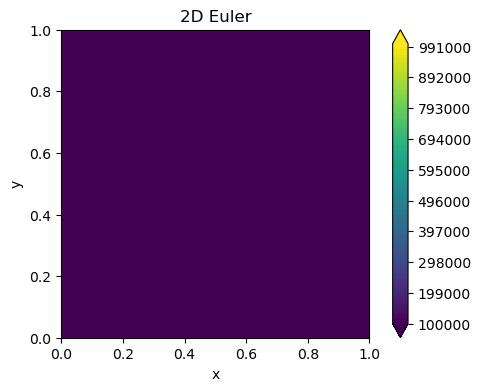

In [188]:
# Example code with Conservative Jacobian splitting for 1D Euler equation Sod shock tube problem
# Caution: this scheme is not "conservative"

# Parameters
gamma = 1.4      # Specific heat ratio
nx = 128         # Number of spatial points [x]
ny = 128         # Number of spatial points [y]
L_x = 1.0          # Length of domain
L_y = 1.0          # Length of domain
dx = L_x / (nx - 1)
dy = L_y / (ny - 1)
CFL = 0.5        # CFL number
tend = 4e-2       # Number of time steps

# Free-stream reference conditions
M_in = 2.0
rho_in = 1.2
pres_in = 1e5

# Setup the grid
x_ = np.linspace(0, L_x, nx)
y_ = np.linspace(0, L_y, ny)
x, y = np.meshgrid(x_,y_)
    
# Use the initial condition you want to use
# Here we will just set it to the freestream reference conditions
rho   = np.ones(x.shape)*rho_in
vel_x = np.ones(x.shape)*M_in * np.sqrt(gamma * pres_in / rho_in)
vel_y = np.ones(x.shape)*0.0
prs   = np.ones(x.shape)*pres_in
prim0 = np.array([rho, vel_x, vel_y, prs])

# Set initial conditions
cons0 = Prim2Cons(prim0[0,:,:], prim0[1,:,:], prim0[2,:,:], prim0[3,:,:])

# Initialize exact solution object
gamma = 1.4

# Set up the solution array u
cons = cons0.copy()
prim = prim0.copy()

# Store solution at each time step
prims = [prim.copy()]
conss = [cons.copy()]

# Save L2 norm errors in an array
errors = []

# Set locations for where we have the wall BC due to the step
i_wall = round(0.5*nx)
j_wmax = round(0.1*ny)

time = 0.0
time_write = 0.0
while(time < tend):   
    # Find dt
    speed_sound = np.sqrt(gamma * prim[3,:,:] / prim[0,:,:])
    dt = CFL * dx / (np.max(np.sqrt(prim[1,:,:]**2 + prim[2,:,:]**2)+speed_sound))
    
    # Update time
    time = time + dt
    
    # Numerical solution update
    cons_new = cons.copy()
    prim_new = prim.copy()

    # Time-update (ADD YOUR CHANGES HERE)
    # Use NumPy arrays for fast impl
    cons_new[:,1:-2,1:-2] = cons.copy()[:,1:-2,1:-2] - dt*(\
            (HLLC_x(prim.copy()[0,1:-2,1:-2], prim.copy()[1,1:-2,1:-2], prim.copy()[2,1:-2,1:-2], prim.copy()[3,1:-2,1:-2], \
                    prim.copy()[0,1+1:-2+1,1:-2], prim.copy()[1,1+1:-2+1,1:-2], prim.copy()[2,1+1:-2+1,1:-2], prim.copy()[3,1+1:-2+1,1:-2]) - \
            HLLC_x(prim.copy()[0,1-1:-2-1,1:-2], prim.copy()[1,1-1:-2-1,1:-2], prim.copy()[2,1-1:-2-1,1:-2], prim.copy()[3,1-1:-2-1,1:-2], \
                    prim.copy()[0,1:-2,1:-2], prim.copy()[1,1:-2,1:-2], prim.copy()[2,1:-2,1:-2], prim.copy()[3,1:-2,1:-2]))/dx + \
            (HLLC_y(prim.copy()[0,1:-2,1:-2], prim.copy()[1,1:-2,1:-2], prim.copy()[2,1:-2,1:-2], prim.copy()[3,1:-2,1:-2], \
                    prim.copy()[0,1:-2,1+1:-2+1], prim.copy()[1,1:-2,1+1:-2+1], prim.copy()[2,1:-2,1+1:-2+1], prim.copy()[3,1:-2,1+1:-2+1]) - \
            HLLC_y(prim.copy()[0,1:-2,1-1:-2-1], prim.copy()[1,1:-2,1-1:-2-1], prim.copy()[2,1:-2,1-1:-2-1], prim.copy()[3,1:-2,1-1:-2-1], \
                    prim.copy()[0,1:-2,1:-2], prim.copy()[1,1:-2,1:-2], prim.copy()[2,1:-2,1:-2], prim.copy()[3,1:-2,1:-2]))/dy)

    # Update primitive variables from the new conservative variables
    cons = cons_new.copy()
    prim = Cons2Prim(cons[0,:,:], cons[1,:,:], cons[2,:,:], cons[3,:,:])
    
    # Update supersonic inflow on i=i_in
    # ADD YOUR CHANGES FOR BOUNDARY CONDITIONS
    i_in = 0
    prim[0,i_in,:] = rho_in
    prim[1,i_in,:] = M_in*np.sqrt(gamma*pres_in/rho_in)
    prim[2,i_in,:] = 0.
    prim[3,i_in,:] = pres_in
    
    # Update supersonic outflow on i=i_out
    i_out = -1
    prim[0,i_out,:] = prim[0,i_out-1,:].copy()
    prim[1,i_out,:] = prim[1,i_out-1,:].copy()
    prim[2,i_out,:] = prim[2,i_out-1,:].copy()
    prim[3,i_out,:] = prim[3,i_out-1,:].copy()
    
    # Update wall on j=j_wall (top)
    j_wall = -1
    prim[0,:,j_wall] = prim[0,:,j_wall-1].copy()
    prim[1,:,j_wall] = prim[1,:,j_wall-1].copy()
    prim[2,:,j_wall] = -prim[2,:,j_wall-1].copy()
    prim[3,:,j_wall] = prim[3,:,j_wall-1].copy()
    
    # Update wall on j=j_wall (bottom)
    j_wall = 0
    prim[0,:,j_wall] = prim[0,:,j_wall+1].copy()
    prim[1,:,j_wall] = prim[1,:,j_wall+1].copy()
    prim[2,:,j_wall] = -prim[2,:,j_wall+1].copy()
    prim[3,:,j_wall] = prim[3,:,j_wall+1].copy()

    # Update wall for step
    prim[0,i_wall,:j_wmax] = prim[0,i_wall-1,:j_wmax].copy()
    prim[1,i_wall,:j_wmax] = -prim[1,i_wall-1,:j_wmax].copy()
    prim[2,i_wall,:j_wmax] = prim[2,i_wall-1,:j_wmax].copy()
    prim[3,i_wall,:j_wmax] = prim[3,i_wall-1,:j_wmax].copy()
    
    prim[0,i_wall:,j_wmax] = prim[0,i_wall:,j_wmax+1].copy()
    prim[1,i_wall:,j_wmax] = prim[1,i_wall:,j_wmax+1].copy()
    prim[2,i_wall:,j_wmax] = -prim[2,i_wall:,j_wmax+1].copy()
    prim[3,i_wall:,j_wmax] = prim[3,i_wall:,j_wmax+1].copy()
    
    # Update conservatives back
    # We need to do this since we have updated the primitive variables
    # during the boundary condition update so we need to convert back
    # to conservatives
    cons = Prim2Cons(prim[0,:,:], prim[1,:,:], prim[2,:,:], prim[3,:,:])
    
    # Update the overall solution arrays
    # We will not do this every time step but every 1 ms
    if (time > time_write + 1e-3):
        time_write = time
        conss.append(cons.copy())
        prims.append(prim.copy())

# Animation setup
plt.close()
fig, ax = plt.subplots(figsize=(6.0,4.0))
c = ax.contourf(x, y, prims[0][3,:,:].T, levels=np.linspace(1e5,1e6,101), extend='both')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_aspect('equal')
ax.set_title('2D Euler')
fig.colorbar(c)

def update(frame):
    ax.clear()
    c = ax.contourf(x, y, prims[frame][3,:,:].T, levels=np.linspace(1e5,1e6,101), extend='both')
    ax.set_title(f'2D Euler, Step {frame}')
    return c

anim = FuncAnimation(fig, update, frames=len(prims), blit=False, interval=50)

plt.show()
HTML(anim.to_jshtml())